# 04 — Task 4: Explainable fuzzy classifier on KDEF (10 %)

**Run this notebook in the fuzzy environment** (`.venv-fuzzy`, kernel *Python (ass2-fuzzy)*):
pyFUME needs `numpy==1.24.4`. The geometric features were computed with dlib in notebook 02
and stored in `data/cache/geo_features.npz`, so no OpenCV/dlib is needed here.

**Design.**
* Six hand-crafted, human-understandable geometric features (all distances divided by the
  inter-ocular distance, so they are scale invariant):

| feature | definition (dlib 68 points) | expected to signal |
|---|---|---|
| `mouth_open` | inner-lip distance (62–66) | surprise, fear, (happy) |
| `mouth_width` | lip-corner distance (48–54) | happy (wide), sad/angry (narrow) |
| `eye_open` | eye aspect ratio (Soukupová & Čech) | surprise/fear (wide), happy/disgust (squint) |
| `brow_height` | eye centre → brow centre (vertical) | surprise/fear (raised), angry (lowered) |
| `smile_ratio` | lip-centre y − lip-corner y | happy (corners up), sad (corners down) |
| `brow_distance` | inner-brow distance (21–22) | angry/disgust/sad (frown: brows pulled together) |

* **Model:** one first-order Takagi–Sugeno fuzzy model per emotion (one-vs-rest), identified with
  pyFUME: fuzzy c-means clustering in the 6-D input space → one rule per cluster with Gaussian
  membership functions → local linear consequents fitted by weighted least squares. The predicted
  emotion is the arg-max of the seven model outputs. Each one-vs-rest training set is balanced
  (all images of the emotion + an equal random sample of the others): pyFUME clusters in the
  joint input–output space, and with a 1:6 imbalance the clusters would only describe "the rest".
* The number of rules per model is chosen with subject-wise (GroupKFold) cross-validation.
* The rules are translated into linguistic terms (*low / medium / high*) and checked for
  plausibility; we also check that the membership functions did **not** collapse into one
  "universal" set (which would make the model a plain linear regression).

In [1]:
# Common setup + evaluation helpers (identical in every notebook of the project)
import os, sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             confusion_matrix, classification_report)
from sklearn.model_selection import StratifiedShuffleSplit

sys.path.insert(0, str(Path.cwd()))
try:
    from src import features as F
except ImportError:  # fuzzy environment (no OpenCV/dlib): only cached features are used there
    from types import SimpleNamespace
    F = SimpleNamespace(EMOTIONS=["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"],
                        CACHE_DIR=Path("data") / "cache")

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# SMOKE=1 (environment variable) runs everything on small subsets with reduced grids, to
# check the notebook end-to-end in minutes. The delivered results use SMOKE=0 (default).
SMOKE = os.environ.get("SMOKE", "0") == "1"
SEED = 42
N_JOBS = -1
EMO = F.EMOTIONS
RESULTS_DIR, FIG_DIR, MODEL_DIR = Path("results"), Path("figures"), Path("models")
for d in (RESULTS_DIR, FIG_DIR, MODEL_DIR, F.CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight"})
print(f"SMOKE={SMOKE}")


def metrics(y_true, y_pred):
    return {"acc": accuracy_score(y_true, y_pred),
            "bal_acc": balanced_accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro", labels=range(7), zero_division=0)}


def per_class_f1(y_true, y_pred):
    return pd.Series(f1_score(y_true, y_pred, average=None, labels=range(7), zero_division=0), index=EMO)


_RESULTS = {}


def reset_results(task):
    """Start a fresh results/<task>.csv for this run of the notebook."""
    _RESULTS[task] = []
    (RESULTS_DIR / f"{task}.csv").unlink(missing_ok=True)


def log_result(task, y_true, y_pred, **info):
    """Append one evaluation row (fixed schema) to results/<task>.csv and return it."""
    row = {**info, **{k: round(v, 4) for k, v in metrics(y_true, y_pred).items()}, "n": len(y_true)}
    _RESULTS.setdefault(task, []).append(row)
    pd.DataFrame(_RESULTS[task]).to_csv(RESULTS_DIR / f"{task}.csv", index=False)
    return row


def fixed_table(df, index, columns, value, index_order, column_order):
    """Pivot to a table with a FIXED row/column layout (same x and y in every task)."""
    t = df.pivot_table(index=index, columns=columns, values=value, aggfunc="first")
    return t.reindex(index=index_order, columns=column_order)


def save_table(df, name, float_format="%.3f"):
    """Save a table as CSV and as a LaTeX tabular (pasted into report/*.md)."""
    df.to_csv(RESULTS_DIR / f"{name}.csv")
    with open(RESULTS_DIR / f"{name}.tex", "w", encoding="utf-8") as f:
        f.write(df.to_latex(float_format=float_format, na_rep="--"))
    return df


def plot_cm(y_true, y_pred, title="", ax=None, normalize=True):
    cm = confusion_matrix(y_true, y_pred, labels=range(7), normalize="true" if normalize else None)
    ax = ax or plt.subplots(figsize=(4.2, 3.6))[1]
    sns.heatmap(cm, annot=True, fmt=".2f" if normalize else "d", cmap="Blues", cbar=False,
                xticklabels=[e[:3] for e in EMO], yticklabels=[e[:3] for e in EMO], ax=ax,
                vmin=0, vmax=1 if normalize else None, annot_kws={"size": 7})
    ax.set_title(title, fontsize=9); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    return ax


def plot_cm_grid(items, fname, ncols=4):
    """items: list of (title, y_true, y_pred). Saved in figures/ for the report appendix."""
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.7 * nrows), squeeze=False)
    for ax, (title, yt, yp) in zip(axes.ravel(), items):
        plot_cm(yt, yp, title, ax=ax)
    for ax in axes.ravel()[len(items):]:
        ax.axis("off")
    fig.tight_layout(); fig.savefig(FIG_DIR / fname); plt.show()


def stratified_subset(y, n, seed=SEED):
    """Indices of a stratified random subset of size n (all indices if n >= len(y))."""
    if n is None or n >= len(y):
        return np.arange(len(y))
    sss = StratifiedShuffleSplit(n_splits=1, train_size=n, random_state=seed)
    return np.sort(next(sss.split(np.zeros(len(y)), y))[0])


def scores(model, X):
    """Class scores for confidence analyses (predict_proba, else softmax(decision_function))."""
    if hasattr(model, "predict_proba"):
        try:
            return model.predict_proba(X)
        except AttributeError:
            pass
    d = model.decision_function(X)
    e = np.exp(d - d.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def save_bundle(name, model, spec, **extra):
    """Persist a FITTED model together with the feature spec needed to use it (demo, other tasks)."""
    bundle = {"model": model, "spec": spec, "labels": EMO, **extra}
    joblib.dump(bundle, MODEL_DIR / f"{name}.pkl", compress=3)
    print(f"saved models/{name}.pkl")


def show_images(imgs, titles=None, ncols=8, size=1.5, fname=None, suptitle=None, cmap="gray"):
    nrows = int(np.ceil(len(imgs) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * 1.15 * nrows), squeeze=False)
    for i, ax in enumerate(axes.ravel()):
        ax.axis("off")
        if i < len(imgs):
            ax.imshow(imgs[i], cmap=None if imgs[i].ndim == 3 else cmap, vmin=0, vmax=255)
            if titles is not None:
                ax.set_title(titles[i], fontsize=7)
    if suptitle:
        fig.suptitle(suptitle, fontsize=10)
    fig.tight_layout()
    if fname:
        fig.savefig(FIG_DIR / fname)
    plt.show()

Matplotlib is building the font cache; this may take a moment.


SMOKE=False


In [2]:
from pyfume import pyFUME
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
import contextlib, io

for t in ("task4_fuzzy", "task4_cv"):
    reset_results(t)
geo = dict(np.load(F.CACHE_DIR / "geo_features.npz", allow_pickle=True))
ALL_NAMES = list(geo["names"])
FUZZY_FEATS = ["mouth_open", "mouth_width", "eye_open", "brow_height", "smile_ratio", "brow_distance"]
cols = [ALL_NAMES.index(f) for f in FUZZY_FEATS]
X_tr_raw, y_tr = geo["X_kdef_train"][:, cols], geo["y_kdef_train"]
X_te_raw, y_te = geo["X_kdef_test"][:, cols], geo["y_kdef_test"]
groups = geo["subj_kdef_train"]
scaler = MinMaxScaler().fit(X_tr_raw)            # inputs in [0, 1]: linguistic terms are comparable
X_tr, X_te = scaler.transform(X_tr_raw), np.clip(scaler.transform(X_te_raw), -0.25, 1.25)
print(X_tr.shape, X_te.shape)

(784, 6) (196, 6)


## 1. Are the six features informative? (class means and ANOVA F)

In [3]:
from sklearn.feature_selection import f_classif
Fstat, pval = f_classif(X_tr, y_tr)
means = pd.DataFrame(X_tr, columns=FUZZY_FEATS).groupby(np.array(EMO)[y_tr]).mean().reindex(EMO)
means.loc["ANOVA F"] = Fstat
save_table(means, "task4_feature_means"); display(means.round(3))
fig, axes = plt.subplots(1, 6, figsize=(17, 2.8))
for ax, f in zip(axes, FUZZY_FEATS):
    sns.boxplot(x=np.array([e[:3] for e in EMO])[y_tr], y=X_tr[:, FUZZY_FEATS.index(f)], ax=ax, order=[e[:3] for e in EMO],
                fliersize=1)
    ax.set_title(f, fontsize=9); ax.tick_params(axis="x", labelsize=7)
fig.tight_layout(); fig.savefig(FIG_DIR / "task4_feature_boxplots.png"); plt.show()

,mouth_open,mouth_width,eye_open,brow_height,smile_ratio,brow_distance
Angry,0.155000,0.28900,0.473000,0.263000,0.384000,0.386
Disgust,0.281000,0.39000,0.353000,0.291000,0.446000,0.522
Fear,0.285000,0.34100,0.577000,0.504000,0.371000,0.483
Happy,0.401000,0.74400,0.371000,0.416000,0.683000,0.593
Sad,0.124000,0.34200,0.484000,0.468000,0.345000,0.412
Surprise,0.398000,0.22400,0.685000,0.664000,0.372000,0.632
Neutral,0.077000,0.29700,0.535000,0.453000,0.294000,0.500
ANOVA F,85.841003,262.05899,116.875999,109.300003,112.386002,37.264


<Figure size 1700x280 with 6 Axes>

## 2. One-vs-rest Takagi–Sugeno models with pyFUME

In [4]:
def train_ovr_fuzzy(X, y, n_rules, order="first", seed=SEED):
    """Seven pyFUME TS models (one per emotion). pyFUME's internal hold-out split is disabled
    (percentage_training=1.0) because we evaluate on our own subject-independent split, and
    Setnes' simplification is disabled (setnes_threshold=1.0): with only 6 inputs it can remove
    every fuzzy set of a variable, which simpful rejects, and every rule should keep one fuzzy
    set per variable so it can be read as a linguistic IF-THEN rule."""
    models = []
    for c in range(7):
        # balanced one-vs-rest set: all images of emotion c + as many images of the other emotions
        # (otherwise the 1:6 imbalance makes the clusters describe the "rest" class only)
        rng = np.random.default_rng(seed + c)
        pos, neg = np.where(y == c)[0], np.where(y != c)[0]
        idx = np.concatenate([pos, rng.choice(neg, min(len(pos), len(neg)), replace=False)])
        np.random.seed(seed + c)
        d = pd.DataFrame(X[idx], columns=FUZZY_FEATS); d["target"] = (y[idx] == c).astype(float)
        with contextlib.redirect_stdout(io.StringIO()):       # pyFUME is very verbose
            m = pyFUME(dataframe=d, nr_clus=n_rules, method="Takagi-Sugeno", model_order=order,
                       percentage_training=1.0, merge_threshold=1.0, setnes_threshold=1.0,
                       save_simpful_code=False)
        models.append(m)
    return models


def ovr_outputs(models, X):
    """Vectorised TS inference: sum_r w_r(x) * (theta_r . [x, 1]); identical to pyFUME's predict_label."""
    out = []
    for m in models:
        w = m.get_firing_strengths(X)                     # normalised firing strength per rule
        theta = np.asarray(m.FIS.consequent_parameters)    # (rules, n_features + 1) or (rules,) for zero order
        local = np.c_[X, np.ones(len(X))] @ theta.T if theta.ndim == 2 else np.tile(theta, (len(X), 1))
        out.append(np.nansum(w * local, axis=1))
    return np.column_stack(out)


def predict_ovr(models, X):
    return ovr_outputs(models, X).argmax(1)


# sanity check: our vectorised inference == pyFUME's own predictions
_m = train_ovr_fuzzy(X_tr[:300], y_tr[:300], 2)
assert np.allclose(ovr_outputs(_m[:1], X_te[:20])[:, 0], _m[0].predict_label(X_te[:20]), atol=1e-6)

['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']


### Number of rules (and consequent order) by subject-wise cross-validation

In [5]:
RULES = [2, 3] if SMOKE else [2, 3, 4, 5]
ORDERS = ["first"] if SMOKE else ["zero", "first"]
cv_rows = []
for order in ORDERS:
    for k in RULES:
        f1s = []
        for tr_i, va_i in GroupKFold(5).split(X_tr, y_tr, groups):
            ms = train_ovr_fuzzy(X_tr[tr_i], y_tr[tr_i], k, order)
            f1s.append(f1_score(y_tr[va_i], predict_ovr(ms, X_tr[va_i]), average="macro"))
        cv_rows.append({"order": order, "rules": k, "cv_f1": np.mean(f1s), "cv_std": np.std(f1s)})
        print(order, k, round(np.mean(f1s), 3))
cv = pd.DataFrame(cv_rows)
save_table(cv.set_index(["order", "rules"]), "task4_cv"); display(cv.round(3))
best_cv = cv.loc[cv.cv_f1.idxmax()]
N_RULES, ORDER = int(best_cv.rules), best_cv.order
print("selected:", ORDER, "order,", N_RULES, "rules per emotion")

['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio

,order,rules,cv_f1,cv_std
0,zero,2,0.248,0.035
1,zero,3,0.252,0.023
2,zero,4,0.303,0.037
3,zero,5,0.318,0.026
4,first,2,0.599,0.019
5,first,3,0.597,0.017
6,first,4,0.590,0.017
7,first,5,0.593,0.022


selected: first order, 2 rules per emotion


['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
              precision    recall  f1-score   support

       Angry      0.650     0.464     0.542        28
     Disgust      0.826     0.679     0.745        28
        Fear      0.450     0.321     0.375        28
       Happy      0.963     0.929     0.945        28
         Sad      0.424     0.500     0.459        28
    Surprise      0.615     0.857     0.716        28
     Neutral      0.588   

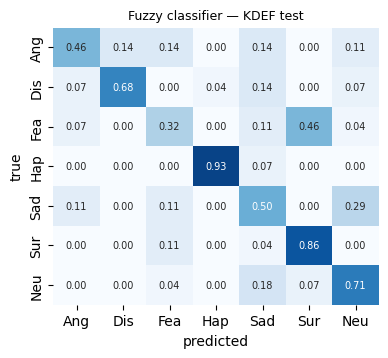

In [6]:
fuzzy = train_ovr_fuzzy(X_tr, y_tr, N_RULES, ORDER)
p_fuzzy = predict_ovr(fuzzy, X_te)
log_result("task4_fuzzy", y_te, p_fuzzy, model=f"Fuzzy TS ({ORDER}, {N_RULES} rules/class)", features="6 geometric", test="KDEF test")
print(classification_report(y_te, p_fuzzy, target_names=EMO, digits=3))
plot_cm(y_te, p_fuzzy, "Fuzzy classifier — KDEF test"); plt.savefig(FIG_DIR / "task4_fuzzy_cm.png"); plt.show()

## 3. Comparison with crisp classifiers
Same six features (scaled identically), then the best KDEF model of Task 2 on its full feature set.

In [7]:
for name, clf in [("LR", LogisticRegression(max_iter=3000, C=1.0)), ("SVM (RBF)", SVC(C=10, gamma="scale"))]:
    pipe = Pipeline([("s", StandardScaler()), ("c", clf)]).fit(X_tr, y_tr)
    log_result("task4_fuzzy", y_te, pipe.predict(X_te), model=name, features="6 geometric", test="KDEF test")
pipe = Pipeline([("s", StandardScaler()), ("c", LogisticRegression(max_iter=3000))]).fit(geo["X_kdef_train"], y_tr)
log_result("task4_fuzzy", y_te, pipe.predict(geo["X_kdef_test"]), model="LR", features="all 20 geometric", test="KDEF test")
t2 = pd.read_csv(RESULTS_DIR / "task2_grid.csv")
b = t2.loc[t2.cv_f1.idxmax()]
_RESULTS["task4_fuzzy"].append({"model": f"{b.model} (Task 2 best)", "features": b.feature, "test": "KDEF test",
                                "acc": b.acc, "bal_acc": b.bal_acc, "macro_f1": b.macro_f1, "n": b.n})
# bonus: the KDEF fuzzy model applied to FER2013 (cross-dataset)
X_fer = np.clip(scaler.transform(geo["X_fer_test"][:, cols]), -0.25, 1.25)
log_result("task4_fuzzy", geo["y_fer_test"], predict_ovr(fuzzy, X_fer), model=f"Fuzzy TS ({ORDER}, {N_RULES} rules/class)",
           features="6 geometric", test="FER test (cross-dataset)")
cmp_tab = pd.DataFrame(_RESULTS["task4_fuzzy"]).set_index(["model", "features", "test"])
save_table(cmp_tab, "task4_comparison"); display(cmp_tab.round(3))

['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']


,,,acc,bal_acc,macro_f1,n
model,features,test,,,,
"Fuzzy TS (first, 2 rules/class)",6 geometric,KDEF test,0.638,0.638,0.632,196
LR,6 geometric,KDEF test,0.638,0.638,0.626,196
SVM (RBF),6 geometric,KDEF test,0.587,0.587,0.576,196
LR,all 20 geometric,KDEF test,0.684,0.684,0.669,196
LR (Task 2 best),HOG+LM,KDEF test,0.638,0.638,0.637,196
"Fuzzy TS (first, 2 rules/class)",6 geometric,FER test (cross-dataset),0.317,0.304,0.289,3589


## 4. The rules in words
Each rule's Gaussian membership function centre is translated into a linguistic term using the
[0, 1] min-max scale of the training data: *low* (< 0.33), *medium*, *high* (> 0.67). The
consequent is summarised by the rule's mean output on the training samples it fires for
(≈ "how much this rule votes for the emotion"). We print the rule with the strongest vote.

In [8]:
def term(mu):
    return "low" if mu < 0.33 else ("high" if mu > 0.67 else "medium")


rule_rows, collapse = [], []
for c, m in enumerate(fuzzy):
    ante = m.FIS.antecedent_parameters
    k = m.FIS.nr_clus
    w = m.get_firing_strengths(X_tr)
    theta = np.asarray(m.FIS.consequent_parameters)
    local = np.c_[X_tr, np.ones(len(X_tr))] @ theta.T if theta.ndim == 2 else np.tile(theta, (len(X_tr), 1))
    for r in range(k):
        mus = [ante[v * k + r][1][0] for v in range(len(FUZZY_FEATS))]
        sig = [ante[v * k + r][1][1] for v in range(len(FUZZY_FEATS))]
        collapse += sig
        vote = float(np.average(local[:, r], weights=w[:, r]))
        support = float(np.average(y_tr == c, weights=w[:, r]))      # share of the target emotion among firing samples
        rule_rows.append({"emotion": EMO[c], "rule": r + 1, "vote": vote, "target_share": support,
                          **{f: f"{term(mu)} ({mu:.2f})" for f, mu in zip(FUZZY_FEATS, mus)}})
rules = pd.DataFrame(rule_rows)
save_table(rules.set_index(["emotion", "rule"]), "task4_rules", float_format="%.2f")
pd.set_option("display.width", 250); display(rules.round(2))
print(f"Membership-function widths: median sigma = {np.median(collapse):.3f}, max = {np.max(collapse):.3f} "
      f"(inputs span [0,1]; sigma >> 1 would mean collapsed, non-informative fuzzy sets)")

['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']
['mouth_open' 'mouth_width' 'eye_open' 'brow_height' 'smile_ratio'
 'brow_distance']


,emotion,rule,vote,target_share,mouth_open,mouth_width,eye_open,brow_height,smile_ratio,brow_distance
0,Angry,1,0.33,0.13,low (0.27),medium (0.46),medium (0.51),medium (0.54),medium (0.52),medium (0.56)
1,Angry,2,0.39,0.16,low (0.19),medium (0.36),medium (0.44),low (0.28),medium (0.34),medium (0.35)
2,Disgust,1,0.32,0.13,low (0.09),medium (0.37),medium (0.57),medium (0.47),medium (0.37),medium (0.52)
3,Disgust,2,0.35,0.15,low (0.32),medium (0.44),medium (0.35),low (0.27),medium (0.50),medium (0.50)
4,Fear,1,0.48,0.15,low (0.30),medium (0.34),medium (0.61),medium (0.59),medium (0.36),medium (0.47)
5,Fear,2,0.44,0.14,low (0.11),medium (0.40),medium (0.41),medium (0.42),medium (0.41),medium (0.47)
6,Happy,1,0.38,0.27,medium (0.43),high (0.76),medium (0.36),medium (0.48),high (0.72),medium (0.67)
7,Happy,2,0.11,0.06,low (0.14),low (0.32),medium (0.61),medium (0.47),medium (0.34),medium (0.45)
8,Sad,1,0.43,0.15,low (0.20),medium (0.46),medium (0.49),medium (0.45),medium (0.40),medium (0.41)
9,Sad,2,0.40,0.14,low (0.21),medium (0.40),medium (0.49),medium (0.41),medium (0.42),medium (0.48)


Membership-function widths: median sigma = 0.482, max = 0.995 (inputs span [0,1]; sigma >> 1 would mean collapsed, non-informative fuzzy sets)


In [9]:
print("Strongest rule per emotion (IF ... THEN emotion):\n")
for emo, g in rules.groupby("emotion", sort=False):
    r = g.loc[g.vote.idxmax()]
    cond = " AND ".join(f"{f} is {r[f].split()[0].upper()}" for f in FUZZY_FEATS)
    print(f"{emo:9s}: IF {cond}\n           THEN {emo} (vote {r.vote:.2f}, {r.target_share:.0%} of firing samples are {emo})\n")

Strongest rule per emotion (IF ... THEN emotion):

Angry    : IF mouth_open is LOW AND mouth_width is MEDIUM AND eye_open is MEDIUM AND brow_height is LOW AND smile_ratio is MEDIUM AND brow_distance is MEDIUM
           THEN Angry (vote 0.39, 16% of firing samples are Angry)

Disgust  : IF mouth_open is LOW AND mouth_width is MEDIUM AND eye_open is MEDIUM AND brow_height is LOW AND smile_ratio is MEDIUM AND brow_distance is MEDIUM
           THEN Disgust (vote 0.35, 15% of firing samples are Disgust)

Fear     : IF mouth_open is LOW AND mouth_width is MEDIUM AND eye_open is MEDIUM AND brow_height is MEDIUM AND smile_ratio is MEDIUM AND brow_distance is MEDIUM
           THEN Fear (vote 0.48, 15% of firing samples are Fear)

Happy    : IF mouth_open is MEDIUM AND mouth_width is HIGH AND eye_open is MEDIUM AND brow_height is MEDIUM AND smile_ratio is HIGH AND brow_distance is MEDIUM
           THEN Happy (vote 0.38, 27% of firing samples are Happy)

Sad      : IF mouth_open is LOW AND mo

### Membership functions of the strongest rules

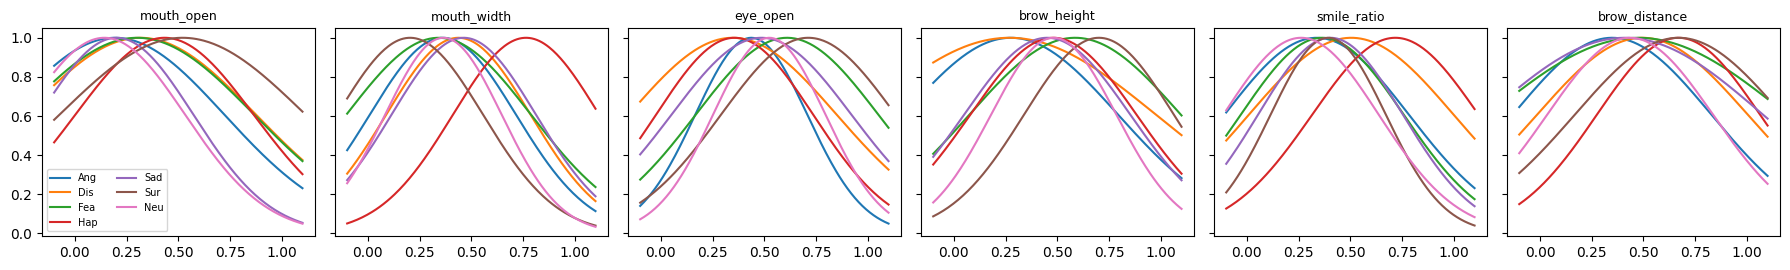

In [10]:
xs = np.linspace(-0.1, 1.1, 200)
fig, axes = plt.subplots(1, 6, figsize=(18, 2.8), sharey=True)
for v, (ax, f) in enumerate(zip(axes, FUZZY_FEATS)):
    for c, m in enumerate(fuzzy):
        k = m.FIS.nr_clus
        g = rules[rules.emotion == EMO[c]]
        r = int(g.loc[g.vote.idxmax(), "rule"]) - 1
        mu, s = m.FIS.antecedent_parameters[v * k + r][1][:2]
        ax.plot(xs, np.exp(-((xs - mu) ** 2) / (2 * s ** 2)), label=EMO[c][:3])
    ax.set_title(f, fontsize=9)
axes[0].legend(fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig(FIG_DIR / "task4_membership_functions.png"); plt.show()

In [11]:
bundle = {"scaler": scaler, "features": FUZZY_FEATS, "n_rules": N_RULES, "order": ORDER, "labels": EMO,
          "antecedents": [m.FIS.antecedent_parameters for m in fuzzy],
          "consequents": [np.asarray(m.FIS.consequent_parameters) for m in fuzzy],
          "rules_table": rules}
try:
    joblib.dump({**bundle, "models": fuzzy}, MODEL_DIR / "task4_fuzzy_kdef.pkl", compress=3)
except Exception as e:  # simpful objects are not always picklable: keep the rule parameters
    print("full pyFUME objects not picklable:", type(e).__name__, "- saving rule parameters only")
    joblib.dump(bundle, MODEL_DIR / "task4_fuzzy_kdef.pkl", compress=3)
print("saved models/task4_fuzzy_kdef.pkl")

saved models/task4_fuzzy_kdef.pkl


## 5. Discussion guide
* **Performance:** compare the fuzzy model with LR/SVM on the *same* six features (cost of
  interpretability vs a black box on the same information) and with the Task 2 model (cost of
  using 6 numbers instead of ~1000 HOG/landmark values).
* **Plausibility check** — expected rules from the Facial Action Coding System (FACS):
  Happy → smile_ratio HIGH, mouth_width HIGH, eye_open LOW (AU6+AU12);
  Surprise → brow_height HIGH, eye_open HIGH, mouth_open HIGH (AU1+2+5+26);
  Fear → brow_height HIGH, eye_open HIGH, mouth_width medium/HIGH (AU1+2+4+5+20);
  Angry → brow_height LOW, brow_distance LOW (AU4), mouth_open LOW;
  Disgust → brow_distance LOW, eye_open LOW, upper lip raised; Sad → smile_ratio LOW (AU15), inner brows up;
  Neutral → everything MEDIUM. Rules that contradict these expectations point at features that
  dlib measures poorly at 48×48, or at emotions that share the same geometry (fear/surprise).
* **Limits:** geometry cannot see texture (wrinkles, nasolabial folds), so disgust/angry/sad
  remain hard; one-vs-rest outputs are not calibrated probabilities.